# 05 · Avaliação e Calibração

O LightGBM venceu os baselines na métrica oficial, mas **prevê ~20% abaixo do volume
real** (viés negativo). Neste notebook:
1. **Calibramos** a previsão para o volume correto em unidades — sem vazamento de dados;
2. Avaliamos o erro por **segmento de negócio** (classe ABC, perecíveis, tipo de loja, família);
3. Traduzimos o erro em linguagem de estoque: **falta × excesso** por quinzena.

## 1. Setup e carga
- **Conjunto de calibração:** o corte de **12/jun** (último do treino). Ele foi usado
  apenas para o *early stopping* — o modelo não aprendeu com ele —, e seus alvos
  (12/jun a 11/jul) terminam antes da validação.
- **Validação:** corte de 17/jul, com as previsões do LightGBM salvas no notebook 04.

In [1]:
import sys
sys.path.append("..")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.models import national_holidays, predict_saved, to_long
from src.calibration import fit_calibration, apply_calibration
from src.metrics import summarize, segment_report, stock_impact
from src.data import FAMILY_PT

PROC = Path("../data/processed")
FIG = Path("../reports/figures")
MODELS = Path("../models")

# Conjunto de calibração = último corte do treino (12/jun)
df_train = pd.read_parquet(PROC / "features_train.parquet")
df_cal = df_train[df_train["cutoff"] == df_train["cutoff"].max()].reset_index(drop=True)
del df_train

df_val = pd.read_parquet(PROC / "features_val.parquet")
lgb_val = np.load(PROC / "lgbm_val_preds.npy")
holidays = national_holidays(pd.read_parquet(PROC / "holidays.parquet"))
items = pd.read_parquet(PROC / "items.parquet")
stores = pd.read_parquet(PROC / "stores.parquet")

# Código numérico da família -> nome (mesma ordem usada em src/features.py)
fam_names = dict(enumerate(items["family"].astype("category").cat.categories))

FMT = {"NWRMSLE": "{:.4f}", "WAPE diário": "{:.1%}", "WAPE quinzenal": "{:.1%}", "Viés": "{:+.1%}"}
print(f"Calibração (corte {df_cal['cutoff'].iloc[0]:%d/%m}): {len(df_cal):,} linhas | "
      f"Validação (corte {df_val['cutoff'].iloc[0]:%d/%m}): {len(df_val):,} linhas")

Calibração (corte 12/06): 167,515 linhas | Validação (corte 17/07): 167,515 linhas


## 2. Previsões no período de calibração
Carregamos os 30 modelos salvos e prevemos o corte de 12/jun. Antes, uma checagem:
os modelos salvos precisam reproduzir **exatamente** as previsões do notebook 04.

In [2]:
check = predict_saved(df_val, holidays, MODELS, horizons=[1])
print(f"Checagem — diferença máxima vs. notebook 04: {np.abs(check[:, 0] - lgb_val[:, 0]).max():.6f}")

cal_preds = predict_saved(df_cal, holidays, MODELS)
print(f"Previsões de calibração: {cal_preds.shape}")

Checagem — diferença máxima vs. notebook 04: 0.000000
Previsões de calibração: (167515, 30)


## 3. Fatores de calibração
`fator = unidades reais ÷ unidades previstas`, medido no período de calibração.
Testamos duas versões:
- **Global por horizonte:** um fator para cada dia à frente (30 fatores);
- **Por família e quinzena:** um fator por família de produtos em cada quinzena
  (66 fatores) — corrige famílias com vendas mais irregulares, onde o viés é maior.

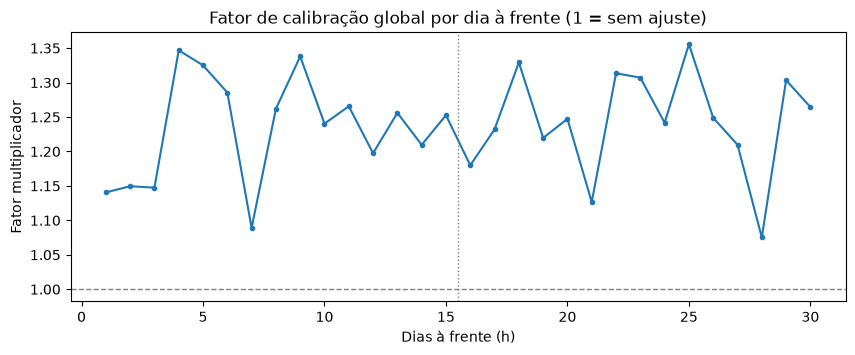

Fator global médio: 1.239  (min 1.075 | máx 1.356)


,1ª quinzena,2ª quinzena
family,,
HOME AND KITCHEN ICasa e cozinha I,1.81,1.62
"LIQUOR,WINE,BEERBebidas alcoólicas",1.75,1.49
LAWN AND GARDENJardinagem,1.66,1.51
LINGERIELingerie,1.58,1.60
GROCERY IIMercearia II,1.46,1.38
CELEBRATIONFestas,1.46,1.47
LADIESWEARModa feminina,1.42,1.35
HARDWAREFerragens,1.39,1.46
PET SUPPLIESPet shop,1.39,1.48


In [3]:
f_glob = fit_calibration(df_cal, cal_preds)
f_fam = fit_calibration(df_cal, cal_preds, by="family")

# Gráfico: fator global por dia à frente
ax = f_glob["fator"].plot(figsize=(10, 3.5), marker="o", ms=3)
ax.axhline(1, color="gray", ls="--", lw=1)
ax.axvline(15.5, color="gray", ls=":", lw=1)
ax.set(title="Fator de calibração global por dia à frente (1 = sem ajuste)",
       xlabel="Dias à frente (h)", ylabel="Fator multiplicador")
plt.savefig(FIG / "05_fator_calibracao.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Fator global médio: {f_glob['fator'].mean():.3f}  "
      f"(min {f_glob['fator'].min():.3f} | máx {f_glob['fator'].max():.3f})")

# Tabela: fatores por família (com tradução em letra menor)
tab = f_fam.rename(index=fam_names).sort_values("1ª quinzena", ascending=False)
tab.style.format("{:.2f}").format_index(
    lambda f: f"{f}<br><small style='color:gray'>{FAMILY_PT.get(f, '')}</small>", axis=0)

### 💡 Insights — Fatores de calibração

1. **A previsão em escala log precisa ser aumentada em ~24% em média** (fator global
   1,239; entre 1,08 e 1,36) para refletir o volume real em unidades.
2. **O tamanho da correção acompanha a irregularidade da demanda:**
   - **Domingos** (h = 7, 21, 28) têm os **menores** fatores (~1,08–1,13): dias de alto
     volume e demanda mais estável;
   - **Quintas-feiras** (h = 4, 18, 25) têm os **maiores** (~1,33–1,36): o dia mais fraco
     e mais irregular da semana (EDA, seção 4);
   - Os **primeiros dias** (h = 1–3) precisam de menos ajuste (~1,15): a incerteza é menor.
3. **Por família, a lógica se repete:**
   - **Itens de giro baixo e irregular** exigem as maiores correções:
     HOME AND KITCHEN I <small>(casa e cozinha)</small> 1,81, LIQUOR,WINE,BEER
     <small>(bebidas alcoólicas)</small> 1,75, LAWN AND GARDEN <small>(jardinagem)</small> 1,66;
   - **Básicos de alto giro** precisam de pouco ajuste: PRODUCE <small>(hortifrúti)</small> 1,19,
     BREAD/BAKERY <small>(padaria)</small> 1,19, DELI <small>(frios)</small> 1,15.
   - BOOKS <small>(livros)</small> é a exceção (0,94 / 0,62): família minúscula, com
     vendas raras — fator instável, de pouca relevância no volume total.

> Por que isso acontece? Quanto mais irregulares as vendas, maior a distância entre a
> "média dos logs" (o que o modelo aprende) e a média real — a desigualdade de Jensen.

## 4. Efeito da calibração na validação
Aplicamos os fatores (estimados em junho) às previsões de julho/agosto e comparamos
as três versões. Atenção ao **trade-off**: a calibração deve corrigir o viés e o erro em
unidades (WAPE), mas pode piorar levemente a métrica em escala log (NWRMSLE).

In [4]:
preds = {
    "LightGBM": lgb_val,
    "LightGBM calibrado (global)": apply_calibration(df_val, lgb_val, f_glob),
    "LightGBM calibrado (família)": apply_calibration(df_val, lgb_val, f_fam, by="family"),
}
long = to_long(df_val, preds)
summarize(long, list(preds)).style.format(FMT)

### 💡 Insights — Efeito da calibração na validação

| 30 dias | LightGBM | Calibrado (família) | Efeito |
|---|---|---|---|
| **Viés** | −20,7% | **−2,6%** | ✅ viés praticamente eliminado |
| **WAPE quinzenal** | 31,1% | **30,2%** | ✅ menor erro no volume da quinzena |
| NWRMSLE | **0,610** | 0,628 | ⚠️ piora de 2,8% na métrica oficial |

1. **A calibração resolve o problema principal:** o viés cai de −20,7% para −2,6%
   (−5,2% na 1ª quinzena e ~0% na 2ª). Os fatores foram estimados em **junho** e
   funcionaram em **julho/agosto**, sem nenhum vazamento.
2. **Trade-off esperado:** a métrica oficial (escala log) piora levemente, porque o
   modelo original era o ótimo *para ela*. **Métrica de competição ≠ métrica de negócio.**
3. **Família × global:** resultados quase idênticos; a versão **por família** tem o
   menor WAPE quinzenal em todos os períodos e é a **escolhida** como modelo final.
4. O viés residual na 1ª quinzena (−5,2%) indica que a 2ª metade de julho vendeu
   um pouco acima do padrão de junho.

## 5. Tradução para estoque: falta × excesso
Somamos previsão e venda real de cada loja × item **por quinzena** — a visão de quem
planeja compras — e separamos o erro em dois tipos:
- **Falta:** demanda não coberta pela previsão → risco de **ruptura** (venda perdida);
- **Excesso:** previsão acima da demanda → risco de **estoque parado e perdas**.

In [5]:
stock_impact(long, list(preds)).style.format({
    "Realizado (unid.)": "{:,.0f}", "Previsto (unid.)": "{:,.0f}",
    "Falta (% do real)": "{:.1%}", "Excesso (% do real)": "{:.1%}"})

,,Realizado (unid.),Previsto (unid.),Falta (% do real),Excesso (% do real)
Quinzena,Modelo,,,,
1ª quinzena,LightGBM,"12,552,475","9,690,690",26.4%,3.6%
2ª quinzena,LightGBM,"12,433,958","10,119,711",25.5%,6.9%
1ª quinzena,LightGBM calibrado (global),"12,552,475","11,895,764",16.3%,11.1%
2ª quinzena,LightGBM calibrado (global),"12,433,958","12,458,293",16.7%,16.9%
1ª quinzena,LightGBM calibrado (família),"12,552,475","11,894,577",16.2%,11.0%
2ª quinzena,LightGBM calibrado (família),"12,433,958","12,439,461",16.6%,16.6%


### 💡 Insights — Falta × excesso de estoque

| | Falta (ruptura) | Excesso (estoque parado) | Erro total |
|---|---|---|---|
| **LightGBM, 1ª quinzena** | 26,4% | 3,6% | 30,0% |
| **Calibrado, 1ª quinzena** | **16,2%** | 11,0% | **27,2%** |
| **LightGBM, 2ª quinzena** | 25,5% | 6,9% | 32,4% |
| **Calibrado, 2ª quinzena** | **16,6%** | 16,6% | 33,2% |

1. **Sem calibração, o erro é quase todo "falta":** a previsão cobriria só ~78% da
   demanda (9,7 milhões de unidades previstas contra 12,6 milhões vendidas na
   1ª quinzena) → **ruptura sistemática**.
2. **A calibração equilibra o erro:** a falta cai **~10 pontos percentuais** (de ~26%
   para ~16%), e o excesso sobe. Na 2ª quinzena o erro fica **simétrico** (16,6% / 16,6%).
3. **O erro total muda pouco — o que muda é *para que lado* ele vai.** E essa é uma
   **decisão de negócio**, não estatística:
   - **Não perecíveis** (mercearia, bebidas, limpeza): faltar custa mais que sobrar
     (a venda perdida não volta; o excesso fica para a semana seguinte) →
     **usar a previsão calibrada**, ou até um pouco acima dela;
   - **Perecíveis** (hortifrúti, padaria, carnes): o excesso vira **perda**
     → calibração mais conservadora, com reposição mais frequente.

**Recomendação:** usar a previsão calibrada como base e definir o **nível de serviço
por segmento** — mais alto para itens A e não perecíveis, mais conservador para
perecíveis de vida curta.

## 6. Onde o modelo é confiável? Erro por segmento
Avaliamos o **modelo final (LightGBM calibrado por família)** por classe ABC,
perecibilidade, tipo de loja e família. A classe ABC é recalculada usando **apenas
vendas anteriores à validação** (até 16/jul), para não haver vazamento.

In [6]:
FINAL = "LightGBM calibrado (família)"

# Classe ABC com vendas ANTERIORES ao corte de validação
tr = pd.read_parquet(PROC / "train_2017.parquet", columns=["date", "item_nbr", "unit_sales"])
vol = (tr.loc[tr["date"] < df_val["cutoff"].iloc[0]].groupby("item_nbr")["unit_sales"].sum()
         .astype("float64").sort_values(ascending=False))
del tr
abc = pd.cut(vol.cumsum() / vol.sum(), bins=[0, 0.80, 0.95, 1.01], labels=["A", "B", "C"])

# Segmentos de negócio na tabela de previsões
long["Classe ABC"] = long["item_nbr"].map(abc.astype(str)).fillna("Sem histórico").astype("category")
long["Tipo de loja"] = long["store_nbr"].map(stores.set_index("store_nbr")["type"]).astype("category")
long["Perecível"] = pd.Categorical(np.where(long["perishable"] == 1, "Perecível", "Não perecível"))
long["Família"] = long["family"].map(fam_names).astype("category")

SEG_FMT = {"% do volume": "{:.1%}", "NWRMSLE": "{:.3f}", "WAPE quinzenal": "{:.1%}", "Viés": "{:+.1%}"}
segment_report(long, FINAL, "Classe ABC").style.format(SEG_FMT)

,% do volume,NWRMSLE,WAPE quinzenal,Viés
Classe ABC,,,,
A,79.0%,0.702,28.9%,-1.3%
B,15.3%,0.609,31.6%,-4.6%
C,5.6%,0.482,44.4%,-15.1%
Sem histórico,0.0%,0.484,69.1%,-58.7%


In [7]:
segment_report(long, FINAL, "Perecível").style.format(SEG_FMT)

,% do volume,NWRMSLE,WAPE quinzenal,Viés
Perecível,,,,
Não perecível,67.4%,0.629,33.6%,-5.5%
Perecível,32.6%,0.623,23.1%,+3.4%


In [8]:
segment_report(long, FINAL, "Tipo de loja").style.format(SEG_FMT)

,% do volume,NWRMSLE,WAPE quinzenal,Viés
Tipo de loja,,,,
A,32.9%,0.667,27.0%,+2.1%
B,14.5%,0.641,33.0%,-6.5%
C,15.4%,0.605,35.9%,-12.0%
D,30.5%,0.611,28.7%,+0.3%
E,6.7%,0.644,33.0%,-8.4%


In [9]:
fam_rep = (segment_report(long, FINAL, "Família")
             .sort_values("% do volume", ascending=False).head(15))
fam_rep.style.format(SEG_FMT).format_index(
    lambda f: f"{f}<br><small style='color:gray'>{FAMILY_PT.get(f, '')}</small>", axis=0)

,% do volume,NWRMSLE,WAPE quinzenal,Viés
Família,,,,
GROCERY IMercearia I,29.5%,0.644,31.1%,-0.6%
BEVERAGESBebidas,22.9%,0.711,34.6%,-10.8%
PRODUCEHortifrúti,14.8%,0.652,23.3%,+4.3%
CLEANINGLimpeza,8.2%,0.626,37.1%,-10.3%
DAIRYLaticínios,5.4%,0.591,22.4%,+0.7%
BREAD/BAKERYPadaria,3.5%,0.659,24.9%,+2.9%
POULTRYAves,2.5%,0.718,24.1%,+2.7%
MEATSCarnes,2.4%,0.606,23.6%,+5.3%
PERSONAL CAREHigiene pessoal,2.0%,0.505,30.2%,+0.4%


## 7. Previsto × realizado: volume total da rede por dia
A visão de quem planeja a operação: a soma de todas as lojas e itens, dia a dia,
comparando a venda real com a previsão original e a calibrada.

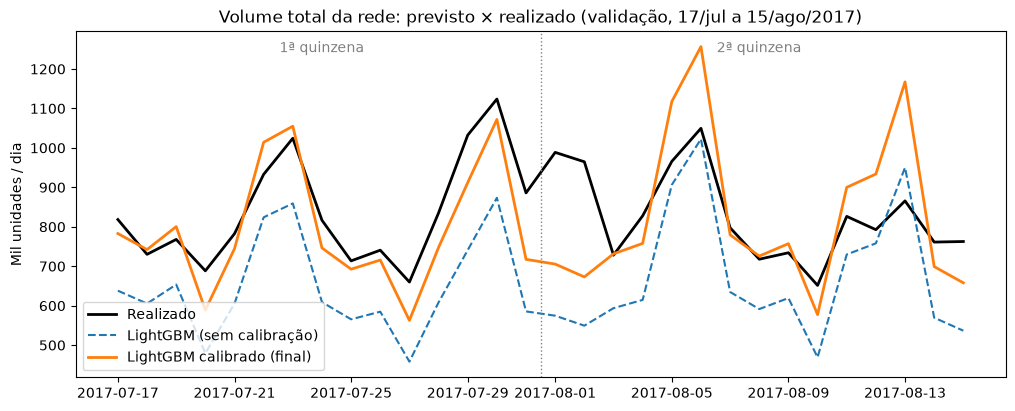

In [10]:
diario = long.groupby("date")[["y_true", "LightGBM", FINAL]].agg(
    lambda s: np.expm1(s.to_numpy("float64")).sum()) / 1000

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(diario.index, diario["y_true"], color="black", lw=2, label="Realizado")
ax.plot(diario.index, diario["LightGBM"], color="C0", ls="--", label="LightGBM (sem calibração)")
ax.plot(diario.index, diario[FINAL], color="C1", lw=2, label="LightGBM calibrado (final)")
ax.axvline(pd.Timestamp("2017-07-31") + pd.Timedelta(hours=12), color="gray", ls=":", lw=1)
ax.text(pd.Timestamp("2017-07-24"), ax.get_ylim()[1] * 0.98, "1ª quinzena", ha="center", va="top", color="gray")
ax.text(pd.Timestamp("2017-08-08"), ax.get_ylim()[1] * 0.98, "2ª quinzena", ha="center", va="top", color="gray")
ax.set(title="Volume total da rede: previsto × realizado (validação, 17/jul a 15/ago/2017)",
       xlabel="", ylabel="Mil unidades / dia")
ax.legend(loc="lower left")
plt.savefig(FIG / "05_previsto_realizado.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Salvar resultados para o painel
Salvamos as previsões finais **em unidades** (por loja × item × dia, com os segmentos)
e os fatores de calibração por família — que serão reutilizados na previsão do futuro.

In [11]:
painel = pd.DataFrame({
    "date": long["date"], "h": long["h"],
    "store_nbr": long["store_nbr"], "item_nbr": long["item_nbr"],
    "family": long["Família"], "store_type": long["Tipo de loja"], "abc": long["Classe ABC"],
    "perishable": long["perishable"].astype("int8"),
    "real": np.expm1(long["y_true"].to_numpy("float64")).astype("float32"),
    "previsto": np.expm1(long[FINAL].to_numpy("float64")).astype("float32"),
})
painel.to_parquet(PROC / "painel_validacao.parquet", index=False)
f_fam.rename(index=fam_names).to_parquet(PROC / "fatores_calibracao.parquet")
print(f"Salvo: {len(painel):,} linhas para o painel + fatores de calibração")

Salvo: 5,025,450 linhas para o painel + fatores de calibração


### 💡 Insights — Onde o modelo é confiável?

**Classe ABC**
| Classe | % do volume | WAPE quinzenal | Viés | Leitura |
|---|---|---|---|---|
| **A** | 79,0% | **28,9%** | −1,3% | ✅ o modelo é mais preciso onde mais importa |
| **B** | 15,3% | 31,6% | −4,6% | bom, com leve subestimação |
| **C** | 5,6% | 44,4% | **−15,1%** | ⚠️ demanda intermitente: erro alto e falta |
| **Sem histórico** | ~0% | 69,1% | −58,7% | ❌ itens lançados durante a validação |

> Note que o NWRMSLE dos itens C é o **menor** (0,482) — porque acertar "zero" em
> escala log é fácil. Para decisão de negócio, o **WAPE** conta a história real.

**Perecibilidade**
| | % do volume | WAPE quinzenal | Viés |
|---|---|---|---|
| **Perecível** | 32,6% | **23,1%** | **+3,4%** (leve excesso → risco de perda) |
| **Não perecível** | 67,4% | 33,6% | **−5,5%** (leve falta → risco de ruptura) |

Os perecíveis são **mais previsíveis** (compra diária e regular), mas o viés de cada
grupo vai para o lado **mais caro** dele: perecíveis tendem a sobrar, não perecíveis
tendem a faltar.

**Tipo de loja**
- **Lojas A e D** (63% do volume) têm o menor erro (27–29%) e viés próximo de zero.
- **Lojas C** — as menores — têm o maior erro (**35,9%**) e **viés de −12%**: menos volume,
  vendas mais irregulares. B e E seguem o mesmo padrão (−6,5% e −8,4%).

**Famílias**
- **Perecíveis básicos são os mais precisos:** DAIRY <small>(laticínios)</small> 22,4%,
  PRODUCE <small>(hortifrúti)</small> 23,3%, MEATS <small>(carnes)</small> 23,6%.
- **BEVERAGES** <small>(bebidas)</small> — 23% do volume — tem **viés de −10,8%**: é a
  família com maior uplift promocional (+60%), e os picos de promoção são subestimados.
  Mesmo padrão em CLEANING <small>(limpeza)</small> (−10,3%).
- **PREPARED FOODS** <small>(comida pronta)</small> fica **+9,4% acima** — num item de vida
  muito curta, isso é **perda direta**.

**Decisões gerenciais**
1. **Itens A:** usar a previsão diretamente para reposição automática — é onde o modelo
   é mais confiável e onde está 79% do volume.
2. **Itens C:** não depender só da previsão: estoque mínimo + reposição sob demanda.
3. **Ajustes finos por segmento:** reduzir ~3% a previsão de perecíveis (sobretudo comida
   pronta) e elevar ~5–10% em não perecíveis promocionais (bebidas, limpeza) e em lojas C.
4. **Lançamentos (sem histórico):** exigem outra abordagem — por exemplo, usar o
   desempenho de itens similares da mesma classe.

### 💡 Insights — Volume total da rede

1. **A calibração corrige o nível:** a previsão original (azul) fica sistematicamente
   **~20% abaixo** do realizado; a calibrada (laranja) acompanha o volume real e reproduz
   bem o **padrão semanal** (picos nos fins de semana, vales às quintas).
2. **1ª quinzena: aderência muito boa** — o modelo acerta nível e ritmo semanal.
3. **Onde o modelo erra, na 2ª quinzena:**
   - **31/jul a 02/ago (início de mês / pagamento):** venda real de ~1 milhão de
     unidades/dia, previsão de ~700 mil → **subestimou o pico do pagamento** em ~30%;
   - **Fins de semana de 05–06/ago e 12–13/ago:** **superestimados** — no segundo caso,
     o fim de semana prolongado pelo feriado da Independência (11/ago) vendeu
     **menos** que um fim de semana normal (famílias viajando).
4. **Lição:** o modelo domina o padrão "normal" (nível + semana), mas **eventos de
   calendário** — pagamento e feriados prolongados — ainda são o principal ponto de
   melhoria. A análise da EDA (seções 5 e 9) já apontava isso.